<a href="https://colab.research.google.com/github/chifa2003/BIGDATA/blob/main/TP2_BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q "dask[dataframe]" pandas psutil matplotlib pyarrow

In [2]:
#التحقق من إمكانية الاتصال بموقع بيانات Amazon Reviews

import requests

# تحديد رابط موقع بيانات تقييمات أمازون
URL = (
    "https://mcauleylab.ucsd.edu/"
    "public_datasets/data/amazon_v2/"
)

try:
      # إرسال طلب GET لجلب محتوى الصفحة من الموقع
    # timeout=20 تعني الانتظار لمدة أقصاها 20 ثانية
    r = requests.get(URL, timeout=20)
        # عرض رمز حالة الاستجابة من الخادم
    # القيمة 200 تعني أن الطلب نجح
    print("HTTP status:", r.status_code)
        # عرض الرابط النهائي الذي تم الوصول إليه
    print("Final URL:", r.url)
    # عرض أول 300 حرف من محتوى الصفحة فقط
    # لتجنب طباعة محتوى الصفحة كاملًا
    print(r.text[:300])
except requests.RequestException as e:
      # معالجة أخطاء الاتصال أو انتهاء مهلة الانتظار
    print("Connection failed:", e)

HTTP status: 200
Final URL: https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/
<html>
  <head>
    <title>Amazon review data</title>
    <meta http-equiv="refresh" content="5; url='https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/'" />
    <meta name="author" content="Jianmo Ni">
    <meta http-equiv="Content-Type" content="text/html; charset=UTF-8">

    <script type="app


In [3]:
#البحث عن روابط ملفات بيانات Amazon Reviews داخل صفحة الموقع

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# تحديد رابط صفحة بيانات Amazon Reviews
page_url = "https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/"

# إرسال طلب لجلب محتوى الصفحة من الموقع
# timeout=30 تعني الانتظار لمدة أقصاها 30 ثانية
response = requests.get(page_url, timeout=30)

# التحقق من نجاح الطلب
# إذا حدث خطأ مثل 404 أو 403، فسيتم رفع استثناء
response.raise_for_status()

# تحليل محتوى الصفحة باستخدام محلل HTML
soup = BeautifulSoup(response.text, "html.parser")

# البحث عن جميع العناصر التي تحتوي على رابط href
for a in soup.find_all("a", href=True):

      # تحويل الرابط إلى رابط كامل حتى لو كان نسبيًا
    href = urljoin(page_url, a["href"])

        # استخراج النص الظاهر داخل الرابط مع إزالة المسافات الزائدة
    text = a.get_text(" ", strip=True)

 # التحقق مما إذا كان نص الرابط أو عنوانه يحتوي على كلمة rating
    # أو إذا كان الرابط يشير إلى ملف بصيغة CSV
    if "rating" in (href + " " + text).lower() or ".csv" in href.lower():

              # عرض اسم الرابط وعنوانه الكامل
        print(text, "->", href)

K-cores and ratings-only data -> https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/#subsets
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/all_csv_files.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/AMAZON_FASHION.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/All_Beauty.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Appliances.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Arts_Crafts_and_Sewing.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Automotive.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Books.csv
ratings only -> https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/CDs_and_Vinyl.csv
ratings only -> 

In [4]:
#التحقق من حجم ملف بيانات Amazon Reviews قبل تحميله

import requests

# تحديد الرابط المباشر لملف بيانات تقييمات أمازون بصيغة CSV
url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/all_csv_files.csv"

 # إرسال طلب HEAD للحصول على معلومات الملف دون تحميل محتواه
    # allow_redirects=True يسمح باتباع التحويلات إلى روابط أخرى
    # timeout=30 يحدد أقصى مدة انتظار بـ 30 ثانية
try:
    r = requests.head(url, allow_redirects=True, timeout=30)

    # عرض رمز حالة استجابة الخادم
    print("Status:", r.status_code)

        # عرض حجم الملف بالبايت إذا كان الخادم يوفر هذه المعلومة
    print("File size in bytes:", r.headers.get("Content-Length"))

    # التحقق من وجود معلومات حجم الملف في ترويسات الاستجابة
    if r.headers.get("Content-Length"):

              # تحويل حجم الملف من البايت إلى الجيجابايت
        size_gb = int(r.headers["Content-Length"]) / 1e9

                # عرض حجم الملف مع تقريب الرقم إلى منزلتين عشريتين
        print(f"File size: {size_gb:.2f} GB")

        # التحقق مما إذا كان حجم الملف يتجاوز 5 جيجابايت
        if size_gb > 5:
            print("Dataset satisfies the 5GB requirement.")
        else:
            print("Dataset is smaller than 5GB.")

                    # عرض رسالة إذا لم يرسل الخادم معلومات حجم الملف
    else:
        print("The server did not provide the file size.")

except Exception as e:

      # معالجة الأخطاء المحتملة أثناء الاتصال بالخادم
    print("Connection error:", e)

Status: 200
File size in bytes: 9726085576
File size: 9.73 GB
Dataset satisfies the 5GB requirement.


In [5]:
#تحميل مجموعة بيانات Amazon Reviews الكبيرة إلى مساحة التخزين المؤقتة

import os
import requests
import time

URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/all_csv_files.csv"
# تحديد المسار الذي سيُحفظ فيه الملف داخل Google Colab
DATA_PATH = "/content/amazon_ratings.csv"

# إرسال طلب لتحميل الملف على شكل أجزاء بدل تحميله كاملًا دفعة واحدة
# stream=True يسمح باستقبال البيانات تدريجيًا
# timeout=60 يحدد مهلة الاتصال بـ 60 ثانية
response = requests.get(URL, stream=True, timeout=60)
response.raise_for_status()

# تهيئة عداد لحساب عدد البايتات التي تم تحميلها
downloaded = 0

# تسجيل وقت بداية التحميل
start = time.time()

# فتح ملف جديد بوضع الكتابة الثنائية لحفظ البيانات كما تصل
with open(DATA_PATH, "wb") as f:

      # قراءة الملف تدريجيًا، بحيث يكون حجم كل جزء 8 ميغابايت
    for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):

              # التأكد من أن الجزء المستلم غير فارغ
        if chunk:

                      # كتابة الجزء الحالي في الملف
            f.write(chunk)

                        # تحديث عدد البايتات التي تم تحميلها
            downloaded += len(chunk)

 # التحقق مما إذا تجاوز التحميل حدًا جديدًا قدره 512 ميغابايت
            # عند تجاوز كل حد جديد، نعرض مقدار البيانات المحمّلة بالجيجابايت
            if downloaded // (512 * 1024 * 1024) != (
                (downloaded - len(chunk)) // (512 * 1024 * 1024)
            ):
                print(f"Downloaded: {downloaded / 1e9:.2f} GB")

# حساب وعرض مدة التحميل بالثواني
print(f"Download completed in {time.time() - start:.1f} seconds")

# الحصول على الحجم النهائي للملف المحفوظ وعرضه بالجيجابايت
print(f"File size: {os.path.getsize(DATA_PATH) / 1e9:.2f} GB")

Downloaded: 0.54 GB
Downloaded: 1.07 GB
Downloaded: 1.61 GB
Downloaded: 2.15 GB
Downloaded: 2.68 GB
Downloaded: 3.22 GB
Downloaded: 3.76 GB
Downloaded: 4.29 GB
Downloaded: 4.83 GB
Downloaded: 5.37 GB
Downloaded: 5.91 GB
Downloaded: 6.44 GB
Downloaded: 6.98 GB
Downloaded: 7.52 GB
Downloaded: 8.05 GB
Downloaded: 8.59 GB
Downloaded: 9.13 GB
Downloaded: 9.66 GB
Download completed in 435.3 seconds
File size: 9.73 GB


In [6]:
#التأكد من أن ملف البيانات amazon_ratings.csv تم تحميله وحفظه بنجاح

import os

# تحديد المسار الذي يُفترض أن ملف البيانات محفوظ فيه
path = "/content/amazon_ratings.csv"

# التحقق مما إذا كان الملف موجودًا في المسار المحدد
print("File exists:", os.path.exists(path))

# إذا كان الملف موجودًا، نحسب حجمه ونعرضه
if os.path.exists(path):

   # الحصول على حجم الملف بالبايت وتحويله إلى جيجابايت
    # نقسم على 1,000,000,000 للحصول على الحجم بوحدة GB
    print(f"File size: {os.path.getsize(path) / 1e9:.2f} GB")

File exists: True
File size: 9.73 GB


In [7]:
import pandas as pd

DATA_PATH = "/content/amazon_ratings.csv"

# قراءة أول 5 أسطر فقط من الملف لمعاينة البيانات

preview = pd.read_csv(
    DATA_PATH,
    header=None, # header=None تعني أن الملف لا يحتوي على أسماء أعمدة في السطر الأول
    nrows=5 # nrows=5 تعني قراءة 5 أسطر فقط دون تحميل الملف كاملًا
)

# عرض معاينة البيانات للتعرف على شكلها ومحتواها
print("Dataset preview:")
display(preview)

# عرض عدد الأعمدة الموجودة في البيانات التي تمت قراءتها
print("\nNumber of columns:", len(preview.columns))

Dataset preview:


,0,1,2,3
0,B00ZGTMHVU,A1HGH7NF01K3W7,5.0,1451001600
1,B013CG1EVC,A3GDQGSD4C0HOB,5.0,1496966400
2,B013CG1EVC,A1C88HIIEVN0QN,5.0,1445904000
3,B013CG1EVC,A1G5MTDE3A5LSL,5.0,1440892800
4,B013CG1XS6,A3SOHSDN51M5NQ,5.0,1441497600



Number of columns: 4


In [8]:
#معالجة ملف Amazon Ratings الذي يتجاوز حجمه 5GB دون الحاجة إلى تحميله كاملًا في الذاكرة
#Task 2: Pandas Chunking

import pandas as pd
import psutil
import time
import threading
import os

# تحديد مسار ملف البيانات
DATA_PATH = "/content/amazon_ratings.csv"

# تحديد عدد الأسطر التي تتم معالجتها في كل جزء
CHUNK_SIZE = 100_000

# تحديد أسماء الأعمدة حسب معاينة ملف البيانات
COL_NAMES = [
    "product_id",  # معرّف المنتج
    "user_id",     # معرّف المستخدم
    "rating",      # تقييم المنتج
    "timestamp"   # الطابع الزمني للتقييم
]

# إنشاء كائن لمراقبة عملية Python الحالية
process = psutil.Process()

# تخزين استهلاك الذاكرة الابتدائي بالبايت
# نستعمل قائمة حتى يمكن تحديث القيمة داخل دالة المراقبة
peak_ram = [process.memory_info().rss]

# متغير للتحكم في استمرار مراقبة الذاكرة
monitor_running = True

# تعريف دالة لمراقبة استهلاك الذاكرة بشكل دوري
def monitor_memory():
    while monitor_running:
        try:
            # قراءة استهلاك الذاكرة الحالي للعملية
            current_ram = process.memory_info().rss

            # الاحتفاظ بأعلى استهلاك للذاكرة تم تسجيله
            peak_ram[0] = max(peak_ram[0], current_ram)

        except psutil.Error:
            # تجاهل أخطاء قراءة معلومات الذاكرة
            pass

        # الانتظار 0.1 ثانية قبل القياس التالي
        time.sleep(0.1)

# إنشاء خيط مستقل لمراقبة الذاكرة
monitor = threading.Thread(
    target=monitor_memory,
    daemon=True
)

# بدء مراقبة الذاكرة
monitor.start()

# تهيئة المتغيرات التي ستجمع نتائج المعالجة
total_rows = 0       # إجمالي عدد الأسطر المعالجة
rating_sum = 0.0     # مجموع التقييمات
rating_count = 0     # عدد التقييمات الصالحة

# تسجيل وقت بداية التنفيذ بدقة
start = time.perf_counter()

try:
    # قراءة الملف على أجزاء بدل تحميله كاملًا في الذاكرة
    # header=None يعني أن الملف لا يحتوي على أسماء أعمدة
    # names=COL_NAMES يحدد أسماء الأعمدة يدويًا
    # chunksize=CHUNK_SIZE يحدد حجم كل جزء بـ 100,000 سطر
    reader = pd.read_csv(
        DATA_PATH,
        header=None,
        names=COL_NAMES,
        chunksize=CHUNK_SIZE
    )

    # معالجة كل جزء من البيانات بالتتابع
    for i, chunk in enumerate(reader, start=1):

        # تحويل عمود التقييمات إلى أرقام
        # القيم غير القابلة للتحويل تصبح مفقودة باستخدام errors="coerce"
        # ثم تُحذف القيم المفقودة باستخدام dropna()
        ratings = pd.to_numeric(
            chunk["rating"], errors="coerce"
        ).dropna()

        # إضافة عدد أسطر الجزء الحالي إلى الإجمالي
        total_rows += len(chunk)

        # إضافة مجموع تقييمات الجزء الحالي إلى المجموع العام
        rating_sum += ratings.sum()

        # إضافة عدد التقييمات الصالحة إلى العدد الإجمالي
        rating_count += ratings.count()

        # عرض تقدم المعالجة كل 20 جزءًا
        if i % 20 == 0:
            print(f"تمت معالجة {total_rows:,} سطر")

    # حساب مدة التنفيذ بعد الانتهاء من معالجة جميع الأجزاء
    chunk_time = time.perf_counter() - start

finally:
    # إيقاف مراقبة الذاكرة بعد انتهاء المعالجة
    monitor_running = False

    # انتظار انتهاء خيط مراقبة الذاكرة لمدة أقصاها ثانيتان
    monitor.join(timeout=2)

# عرض عنوان نتائج معالجة البيانات باستخدام Pandas Chunking

print("\n===== PANDAS CHUNKING RESULTS =====")

# عرض إجمالي عدد الأسطر التي تمت معالجتها
print("Total rows:", f"{total_rows:,}")

# عرض عدد التقييمات الصالحة التي تم استخدامها في الحساب
print("Valid ratings:", f"{rating_count:,}")

# عرض مجموع التقييمات
print("Sum of ratings:", rating_sum)

# حساب وعرض المتوسط العام للتقييمات الصالحة
print(
    "Global mean rating:",
    rating_sum / rating_count if rating_count else None
)

# عرض مدة التنفيذ بالثواني
print(f"Execution time: {chunk_time:.2f} seconds")

# عرض أعلى استهلاك مسجل لذاكرة عملية Python بوحدة MiB
print(f"Peak process RAM: {peak_ram[0] / 1024**2:.2f} MiB")

تمت معالجة 2,000,000 سطر
تمت معالجة 4,000,000 سطر
تمت معالجة 6,000,000 سطر
تمت معالجة 8,000,000 سطر
تمت معالجة 10,000,000 سطر
تمت معالجة 12,000,000 سطر
تمت معالجة 14,000,000 سطر
تمت معالجة 16,000,000 سطر
تمت معالجة 18,000,000 سطر
تمت معالجة 20,000,000 سطر
تمت معالجة 22,000,000 سطر
تمت معالجة 24,000,000 سطر
تمت معالجة 26,000,000 سطر
تمت معالجة 28,000,000 سطر
تمت معالجة 30,000,000 سطر
تمت معالجة 32,000,000 سطر
تمت معالجة 34,000,000 سطر
تمت معالجة 36,000,000 سطر
تمت معالجة 38,000,000 سطر
تمت معالجة 40,000,000 سطر
تمت معالجة 42,000,000 سطر
تمت معالجة 44,000,000 سطر
تمت معالجة 46,000,000 سطر
تمت معالجة 48,000,000 سطر
تمت معالجة 50,000,000 سطر
تمت معالجة 52,000,000 سطر
تمت معالجة 54,000,000 سطر
تمت معالجة 56,000,000 سطر
تمت معالجة 58,000,000 سطر
تمت معالجة 60,000,000 سطر
تمت معالجة 62,000,000 سطر
تمت معالجة 64,000,000 سطر
تمت معالجة 66,000,000 سطر
تمت معالجة 68,000,000 سطر
تمت معالجة 70,000,000 سطر
تمت معالجة 72,000,000 سطر
تمت معالجة 74,000,000 سطر
تمت معالجة 76,000,000 سطر
تمت معالجة 78,00

In [9]:
# معالجة مجموعة بيانات Amazon Ratings الكبيرة باستخدام Dask،
# TASK 3: BIG DATA PROCESSING WITH DASK

# تثبيت مكتبة Dask الخاصة بمعالجة البيانات الضخمة ومكتبة مراقبة الذاكرة
!pip -q install "dask[dataframe]" psutil

import dask
import dask.dataframe as dd
import pandas as pd
import psutil
import time
import threading
import gc

DATA_PATH = "/content/amazon_ratings.csv"

COL_NAMES = [
    "product_id",
    "user_id",
    "rating",
    "timestamp"
]

# ------------------------------------------------------------
# 1. Monitor Python process memory
# ------------------------------------------------------------

# إنشاء كائن لمراقبة العملية الحالية
process = psutil.Process()

# تسجيل استهلاك الذاكرة الابتدائي بالبايت
peak_ram_dask = [process.memory_info().rss]

# متغير للتحكم في استمرار مراقبة الذاكرة
monitor_running_dask = True

# تعريف دالة لمراقبة الذاكرة بشكل دوري
def monitor_dask_memory():
    while monitor_running_dask:
        try:
            # قراءة استهلاك الذاكرة الحالي
            current_ram = process.memory_info().rss

            # الاحتفاظ بأعلى قيمة مسجلة لاستهلاك الذاكرة
            peak_ram_dask[0] = max(
                peak_ram_dask[0],
                current_ram
            )
        except psutil.Error:
            # تجاهل أخطاء قراءة معلومات الذاكرة
            pass

        # الانتظار 0.1 ثانية قبل القياس التالي
        time.sleep(0.1)

# إنشاء خيط مستقل لمراقبة الذاكرة
monitor = threading.Thread(
    target=monitor_dask_memory,
    daemon=True
)

# بدء مراقبة الذاكرة
monitor.start()

# ------------------------------------------------------------
# 2. Create Dask DataFrame (lazy execution)
# ------------------------------------------------------------

# تسجيل وقت بداية العملية
start_dask = time.perf_counter()

# قراءة ملف CSV باستخدام Dask وتقسيمه إلى أجزاء
# header=None يعني أن الملف لا يحتوي على أسماء أعمدة
# names=COL_NAMES يحدد أسماء الأعمدة يدويًا
# blocksize="64 MiB" يحدد الحجم المستهدف لكل جزء
# dtype يحدد نوع البيانات المتوقع في كل عمود
df_dask = dd.read_csv(
    DATA_PATH,
    header=None,
    names=COL_NAMES,
    blocksize="64 MiB",
    dtype={
        "product_id": "object",
        "user_id": "object",
        "rating": "float64",
        "timestamp": "int64"
    }
)

# عرض رسالة تؤكد إنشاء إطار البيانات
print("Dask DataFrame created.")

# عرض عدد الأجزاء التي قُسّم إليها الملف
print("Partitions:", df_dask.npartitions)

# توضيح أن Dask لا ينفذ المعالجة كاملة عند إنشاء الإطار
# بل يؤجل التنفيذ الفعلي حتى استدعاء compute()
print("The operations are lazy until compute() is called.")

# ------------------------------------------------------------
# 3. Define aggregations
# ------------------------------------------------------------

# حساب مجموع التقييمات
rating_sum_dask = df_dask["rating"].sum()

# حساب عدد التقييمات غير المفقودة
rating_count_dask = df_dask["rating"].count()

# حساب عدد السجلات التي تحتوي على معرّف منتج غير مفقود
total_rows_dask = df_dask["product_id"].count()

# ------------------------------------------------------------
# 4. Execute computations
# ------------------------------------------------------------

# تنفيذ الحسابات المطلوبة باستخدام Dask
# scheduler="threads" يسمح بتنفيذ المهام باستخدام الخيوط
results_dask = dask.compute(
    total_rows_dask,
    rating_sum_dask,
    rating_count_dask,
    scheduler="threads"
)

# استخراج النتائج وتحويلها إلى الأنواع المناسبة
total_rows_result = int(results_dask[0])
rating_sum_result = float(results_dask[1])
rating_count_result = int(results_dask[2])

# حساب مدة التنفيذ منذ بداية إنشاء إطار البيانات
dask_time = time.perf_counter() - start_dask

# إيقاف مراقبة الذاكرة بعد انتهاء العمليات
monitor_running_dask = False

# انتظار انتهاء خيط المراقبة لمدة أقصاها ثانيتان
monitor.join(timeout=2)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

# عرض عنوان النتائج
print("\n===== DASK RESULTS =====")

# عرض العدد الإجمالي للسجلات حسب العمود product_id
print("Total rows:", f"{total_rows_result:,}")

# عرض عدد التقييمات غير المفقودة
print("Valid ratings:", f"{rating_count_result:,}")

# عرض مجموع التقييمات
print("Sum of ratings:", rating_sum_result)

# حساب وعرض متوسط التقييمات إذا كان عددها أكبر من صفر
if rating_count_result > 0:
    print(
        "Global mean rating:",
        rating_sum_result / rating_count_result
    )

# عرض مدة التنفيذ بالثواني
print(f"Execution time: {dask_time:.2f} seconds")

# عرض أعلى استهلاك مسجل لذاكرة عملية Python بوحدة MiB
print(
    f"Peak process RAM: "
    f"{peak_ram_dask[0] / 1024**2:.2f} MiB"
)

# ------------------------------------------------------------
# 6. Save Dask results for the final comparison
# ------------------------------------------------------------

# إنشاء جدول يحتوي على نتائج Dask
dask_results_df = pd.DataFrame([{
    "Method": "Dask",
    "Total_Rows": total_rows_result,
    "Rating_Sum": rating_sum_result,

    # حساب المتوسط مع تجنب القسمة على صفر
    "Mean_Rating": (
        rating_sum_result / rating_count_result
        if rating_count_result else None
    ),

    # حفظ مدة التنفيذ
    "Execution_Time_sec": dask_time,

    # حفظ أعلى استهلاك مسجل للذاكرة بوحدة MiB
    "Peak_RAM_MiB": peak_ram_dask[0] / 1024**2
}])

# حفظ جدول النتائج في ملف CSV داخل Google Colab
dask_results_df.to_csv(
    "/content/dask_results.csv",
    index=False
)

# عرض رسالة تؤكد حفظ النتائج
print("\nDask results saved to /content/dask_results.csv")


Dask DataFrame created.
Partitions: 144
The operations are lazy until compute() is called.

===== DASK RESULTS =====
Total rows: 233,055,327
Valid ratings: 233,055,327
Sum of ratings: 986334473.0
Global mean rating: 4.232190208636595
Execution time: 249.60 seconds
Peak process RAM: 1133.44 MiB

Dask results saved to /content/dask_results.csv


In [10]:
#التأكد من أن مكتبة Pandas مثبتة وتعمل بشكل صحيح
import pandas as pd

print("Pandas is ready:", pd.__version__)


Pandas is ready: 2.2.3


In [ ]:
#ختبار قدرة Pandas على تحميل ملف CSV ضخم كاملًا في الذاكرة،
#Task 1: Standard Pandas

import pandas as pd
import os
import time
import psutil
import threading

DATA_PATH = "/content/amazon_ratings.csv"

# التحقق مما إذا كان ملف البيانات موجودًا
if not os.path.exists(DATA_PATH):
    print("Dataset not found. The file must be downloaded again.")

        # عرض رسالة تؤكد العثور على الملف
else:
    print("Dataset found!")

        # عرض حجم الملف بوحدة GiB
    # 1 GiB = 1024^3 بايت
    print("File size:", round(os.path.getsize(DATA_PATH) / (1024**3), 2), "GiB")

    # إنشاء كائن لمراقبة عملية Python الحالية
    process = psutil.Process()

     # تسجيل استهلاك الذاكرة الابتدائي بالبايت
    # سنحتفظ بأعلى قيمة يتم تسجيلها أثناء التنفيذ
    peak_ram = [process.memory_info().rss]

        # متغير للتحكم في استمرار مراقبة الذاكرة
    monitoring = [True]

    # تعريف دالة لمراقبة استهلاك الذاكرة دوريًا
    def monitor_memory():
        while monitoring[0]:
            try:

                              # تحديث أعلى استهلاك مسجل للذاكرة
                peak_ram[0] = max(
                    peak_ram[0],
                          # قراءة استهلاك الذاكرة الحالي
                    process.memory_info().rss
                )
            except psutil.Error:

                              # تجاهل أخطاء قراءة معلومات الذاكرة
                pass

                            # الانتظار 0.1 ثانية قبل القياس التالي
            time.sleep(0.1)

    # إنشاء خيط مستقل لمراقبة الذاكرة
    monitor = threading.Thread(
        target=monitor_memory,
        daemon=True
    )

        # بدء مراقبة الذاكرة
    monitor.start()

    # تسجيل وقت بداية محاولة تحميل الملف
    start = time.perf_counter()

    try:

              # عرض رسالة قبل بدء تحميل البيانات
        print("\nAttempting to load the entire dataset...")

                # قراءة ملف CSV كاملًا دفعة واحدة
        # header=None يعني أن الملف لا يحتوي على أسماء أعمدة
        # names تحدد أسماء الأعمدة الأربعة
        # لا نستخدم chunksize هنا لأن الهدف اختبار القراءة الكاملة
        df_standard = pd.read_csv(
            DATA_PATH,
            header=None,
            names=[
                "product_id",
                "user_id",
                "rating",
                "timestamp"
            ]
        )

        # إذا نجحت القراءة، نعرض حالة النجاح وأبعاد البيانات
        print("Status: SUCCESS")
        print("Shape:", df_standard.shape)

    except MemoryError:

              # عرض رسالة إذا أبلغ Python عن نفاد الذاكرة
        print("Status: FAILED - MemoryError")

    except Exception as e:

              # معالجة الأخطاء الأخرى وعرض نوع الخطأ ورسـالته
        print("Status: FAILED")
        print("Error:", type(e).__name__, str(e))

    finally:

              # حساب المدة المستغرقة منذ بداية محاولة التحميل
        elapsed = time.perf_counter() - start

                # إيقاف مراقبة الذاكرة
        monitoring[0] = False

              # انتظار انتهاء خيط المراقبة لمدة أقصاها ثانيتان
        monitor.join(timeout=2)

        # عرض النتائج النهائية للمحاولة
        print("\n===== STANDARD PANDAS RESULTS =====")

                # عرض مدة التنفيذ بالثواني
        print(f"Execution time: {elapsed:.2f} seconds")

               # عرض أعلى استهلاك مسجل لذاكرة عملية Python بوحدة MiB
        print(
            "Peak process RAM:",
            round(peak_ram[0] / (1024**2), 2),
            "MiB"
        )



Dataset found!
File size: 9.06 GiB

Attempting to load the entire dataset...


Comparison of Big Data Processing Methods:


,Method,Status,Total_Rows,Mean_Rating,Execution_Time_sec,Peak_RAM_MiB
0,Standard Pandas,Runtime crashed: RAM exhausted,NaN,NaN,NaN,NaN
1,Pandas Chunking,Success,233055327.0,4.23219,307.72,1669.09
2,Dask,Success,233055327.0,4.23219,393.94,2484.24


Comparison table saved successfully!


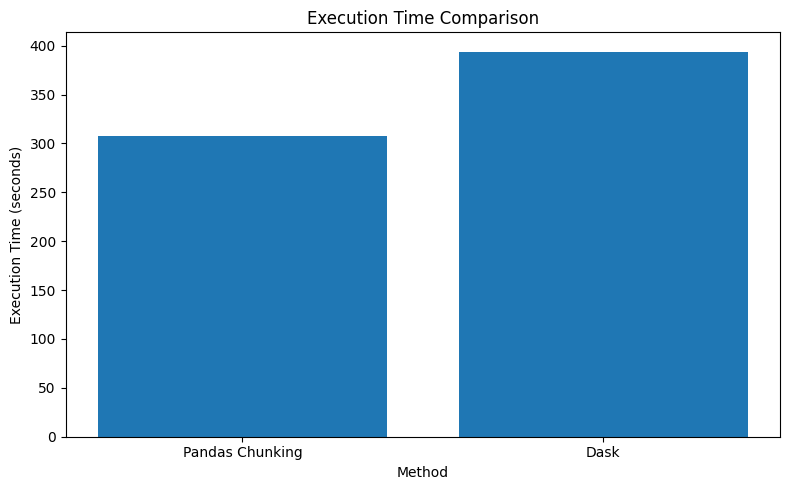

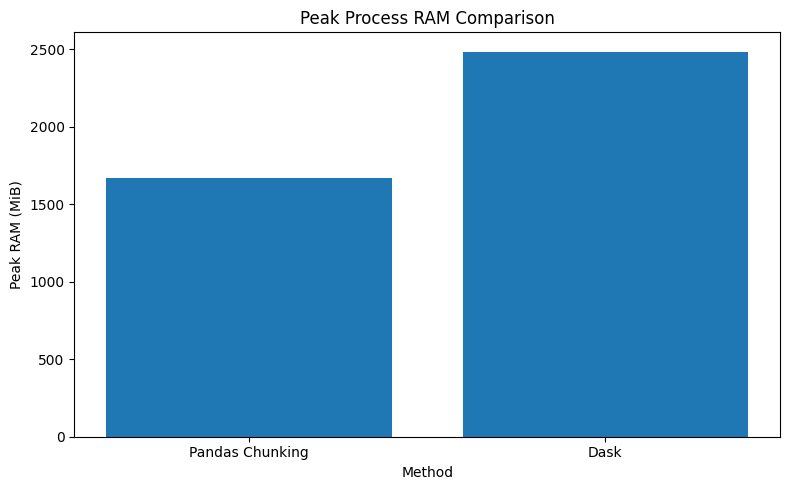

Charts saved successfully!


In [1]:

# ============================================================
# TP02: BIG DATA FILES (+5GB)
# إعادة إنشاء جدول المقارنة باستعمال النتائج السابقة
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. إنشاء جدول النتائج السابقة
comparison = pd.DataFrame({
    "Method": [
        "Standard Pandas",
        "Pandas Chunking",
        "Dask"
    ],
    "Status": [
        "Runtime crashed: RAM exhausted",
        "Success",
        "Success"
    ],
    "Total_Rows": [
        None,
        233055327,
        233055327
    ],
    "Mean_Rating": [
        None,
        4.232190208636595,
        4.232190208636595
    ],
    "Execution_Time_sec": [
        None,
        307.72,
        393.94
    ],
    "Peak_RAM_MiB": [
        None,
        1669.09,
        2484.24
    ]
})

# 2. عرض الجدول
print("Comparison of Big Data Processing Methods:")
display(comparison)

# 3. حفظ النتائج في ملف CSV
comparison.to_csv(
    "/content/comparison_results.csv",
    index=False
)

print("Comparison table saved successfully!")

# 4. رسم مقارنة وقت التنفيذ
successful = comparison[
    comparison["Execution_Time_sec"].notna()
]

plt.figure(figsize=(8, 5))
plt.bar(
    successful["Method"],
    successful["Execution_Time_sec"]
)
plt.title("Execution Time Comparison")
plt.xlabel("Method")
plt.ylabel("Execution Time (seconds)")
plt.tight_layout()
plt.savefig("/content/execution_time_comparison.png", dpi=300)
plt.show()

# 5. رسم مقارنة استهلاك الذاكرة
plt.figure(figsize=(8, 5))
plt.bar(
    successful["Method"],
    successful["Peak_RAM_MiB"]
)
plt.title("Peak Process RAM Comparison")
plt.xlabel("Method")
plt.ylabel("Peak RAM (MiB)")
plt.tight_layout()
plt.savefig("/content/ram_comparison.png", dpi=300)
plt.show()

print("Charts saved successfully!")
